# Credit Card Fraud Detection

## OIBSIP Data Analytics Internship – Level 2 Task 3

### Objective
To develop a Machine Learning model that identifies fraudulent credit card transactions using classification techniques.

### Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Imbalanced-learn
- Jupyter Notebook

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("creditcard.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [4]:
display(df.describe())

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [5]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [6]:
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

Missing Values: 0
Duplicate Rows: 1081


In [7]:
class_counts = df["Class"].value_counts()

print("Transaction Counts:")
print(class_counts)

print("\nTransaction Percentage:")
print((df["Class"].value_counts(normalize=True) * 100).round(4))

Transaction Counts:
Class
0    284315
1       492
Name: count, dtype: int64

Transaction Percentage:
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


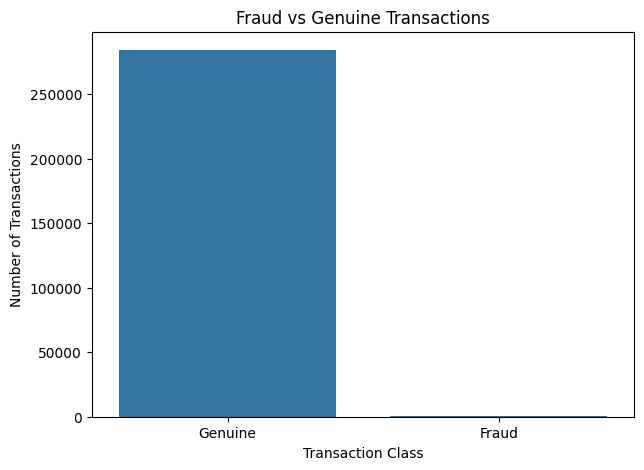

In [8]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Class")

plt.title("Fraud vs Genuine Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Genuine", "Fraud"])

plt.show()

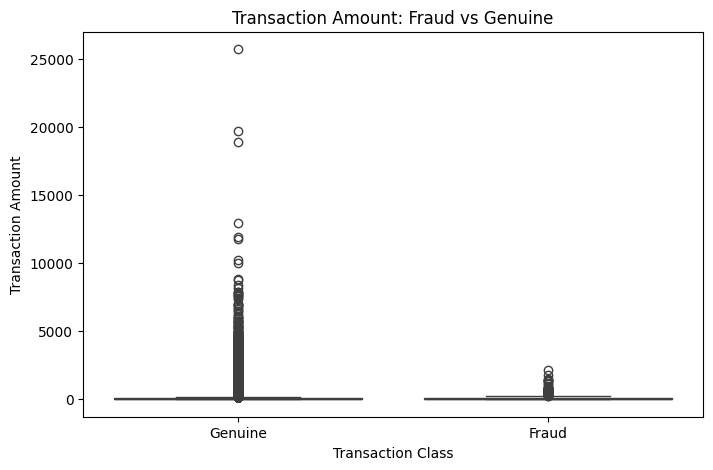

In [9]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Class", y="Amount")

plt.title("Transaction Amount: Fraud vs Genuine")
plt.xlabel("Transaction Class")
plt.ylabel("Transaction Amount")
plt.xticks([0, 1], ["Genuine", "Fraud"])

plt.show()

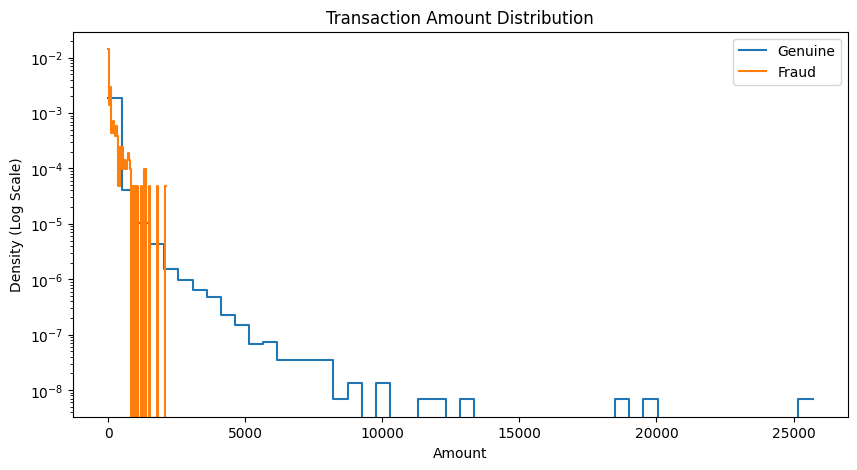

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df[df["Class"] == 0],
    x="Amount",
    bins=50,
    stat="density",
    element="step",
    fill=False,
    label="Genuine"
)

sns.histplot(
    data=df[df["Class"] == 1],
    x="Amount",
    bins=50,
    stat="density",
    element="step",
    fill=False,
    label="Fraud"
)

plt.yscale("log")
plt.title("Transaction Amount Distribution")
plt.xlabel("Amount")
plt.ylabel("Density (Log Scale)")
plt.legend()

plt.show()

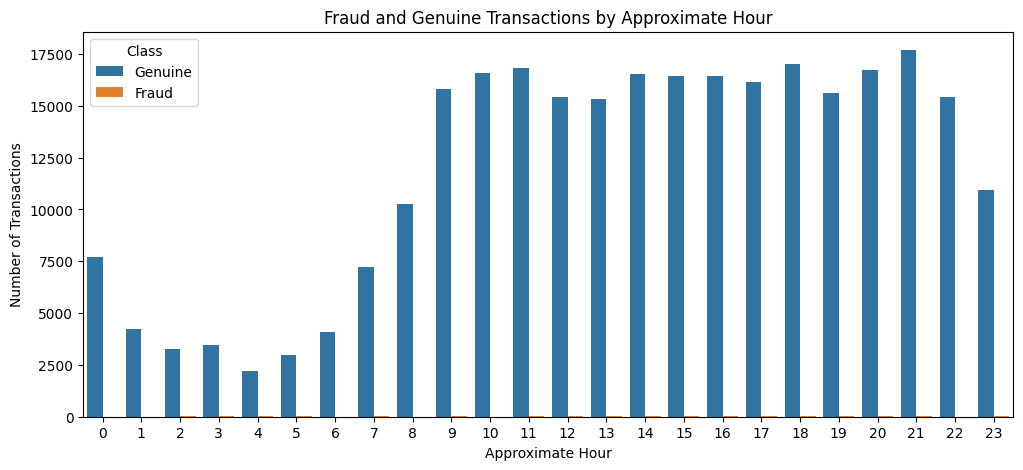

In [11]:
df["Hour"] = ((df["Time"] // 3600) % 24).astype(int)

plt.figure(figsize=(12, 5))

sns.countplot(data=df, x="Hour", hue="Class")

plt.title("Fraud and Genuine Transactions by Approximate Hour")
plt.xlabel("Approximate Hour")
plt.ylabel("Number of Transactions")
plt.legend(title="Class", labels=["Genuine", "Fraud"])

plt.show()

In [12]:
X = df.drop(columns=["Class", "Hour"])
y = df["Class"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (284807, 30)
Target Shape: (284807,)


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (227845, 30)
Testing Shape: (56962, 30)


In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [15]:
%pip install imbalanced-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
from imblearn.over_sampling import SMOTE

print("SMOTE imported successfully!")

SMOTE imported successfully!


In [17]:
smote = SMOTE(random_state=42)

X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_resampled.value_counts())

Before SMOTE:
Class
0    227451
1       394
Name: count, dtype: int64

After SMOTE:
Class
0    227451
1    227451
Name: count, dtype: int64


In [18]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_resampled, y_train_resampled)

lr_pred = lr_model.predict(X_test_scaled)
lr_prob = lr_model.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [24]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=30,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_resampled, y_train_resampled)

rf_pred = rf_model.predict(X_test_scaled)
rf_prob = rf_model.predict_proba(X_test_scaled)[:, 1]

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [26]:
from imblearn.over_sampling import SMOTE

X_small = X_train_scaled[:50000]
y_small = y_train.iloc[:50000]

smote = SMOTE(random_state=42)

X_resampled, y_resampled = smote.fit_resample(
    X_small,
    y_small
)

print("Before SMOTE:")
print(y_small.value_counts())

print("\nAfter SMOTE:")
print(y_resampled.value_counts())

Before SMOTE:
Class
0    49909
1       91
Name: count, dtype: int64

After SMOTE:
Class
0    49909
1    49909
Name: count, dtype: int64


In [27]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=10,
    max_depth=8,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=1
)

rf_model.fit(X_resampled, y_resampled)

rf_pred = rf_model.predict(X_test_scaled)
rf_prob = rf_model.predict_proba(X_test_scaled)[:, 1]

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [28]:
rf_pred = rf_model.predict(X_test_scaled)

rf_prob = rf_model.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [29]:
print("RANDOM FOREST RESULTS")

print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

RANDOM FOREST RESULTS
Accuracy: 0.9963308872581721
Precision: 0.2996389891696751
Recall: 0.8469387755102041
F1 Score: 0.44266666666666665
ROC-AUC: 0.9713288347134014

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.30      0.85      0.44        98

    accuracy                           1.00     56962
   macro avg       0.65      0.92      0.72     56962
weighted avg       1.00      1.00      1.00     56962



In [30]:
rf_pred = rf_model.predict(X_test_scaled)
rf_prob = rf_model.predict_proba(X_test_scaled)[:, 1]

print("Random Forest predictions generated successfully!")

Random Forest predictions generated successfully!


In [31]:
print("RANDOM FOREST RESULTS")

print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

RANDOM FOREST RESULTS
Accuracy: 0.9963308872581721
Precision: 0.2996389891696751
Recall: 0.8469387755102041
F1 Score: 0.44266666666666665
ROC-AUC: 0.9713288347134014

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.30      0.85      0.44        98

    accuracy                           1.00     56962
   macro avg       0.65      0.92      0.72     56962
weighted avg       1.00      1.00      1.00     56962



In [32]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)

lr_model.fit(X_resampled, y_resampled)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [33]:
lr_pred = lr_model.predict(X_test_scaled)
lr_prob = lr_model.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression predictions generated!")

Logistic Regression predictions generated!


In [34]:
print("LOGISTIC REGRESSION RESULTS")

print("Accuracy:", accuracy_score(y_test, lr_pred))
print("Precision:", precision_score(y_test, lr_pred))
print("Recall:", recall_score(y_test, lr_pred))
print("F1 Score:", f1_score(y_test, lr_pred))
print("ROC-AUC:", roc_auc_score(y_test, lr_prob))

print("\nClassification Report:")
print(classification_report(y_test, lr_pred))

LOGISTIC REGRESSION RESULTS
Accuracy: 0.9624662055405357
Precision: 0.04012623985572588
Recall: 0.9081632653061225
F1 Score: 0.0768566493955095
ROC-AUC: 0.9549048463645446

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.96      0.98     56864
           1       0.04      0.91      0.08        98

    accuracy                           0.96     56962
   macro avg       0.52      0.94      0.53     56962
weighted avg       1.00      0.96      0.98     56962



In [35]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, lr_pred),
        precision_score(y_test, rf_pred)
    ],
    "Recall": [
        recall_score(y_test, lr_pred),
        recall_score(y_test, rf_pred)
    ],
    "F1 Score": [
        f1_score(y_test, lr_pred),
        f1_score(y_test, rf_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, lr_prob),
        roc_auc_score(y_test, rf_prob)
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.962466,0.040126,0.908163,0.076857,0.954905
1,Random Forest,0.996331,0.299639,0.846939,0.442667,0.971329


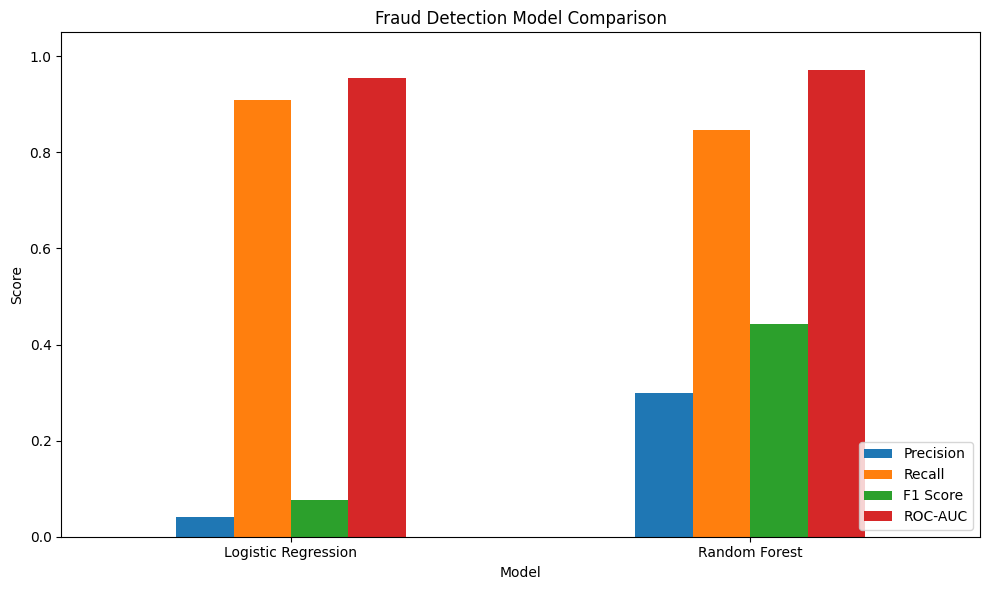

In [36]:
comparison.set_index("Model")[["Precision", "Recall", "F1 Score", "ROC-AUC"]].plot(
    kind="bar", figsize=(10, 6)
)

plt.title("Fraud Detection Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [37]:
import os

os.makedirs("Outputs", exist_ok=True)
comparison.to_csv("Outputs/model_comparison.csv", index=False)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [38]:
from sklearn.metrics import confusion_matrix

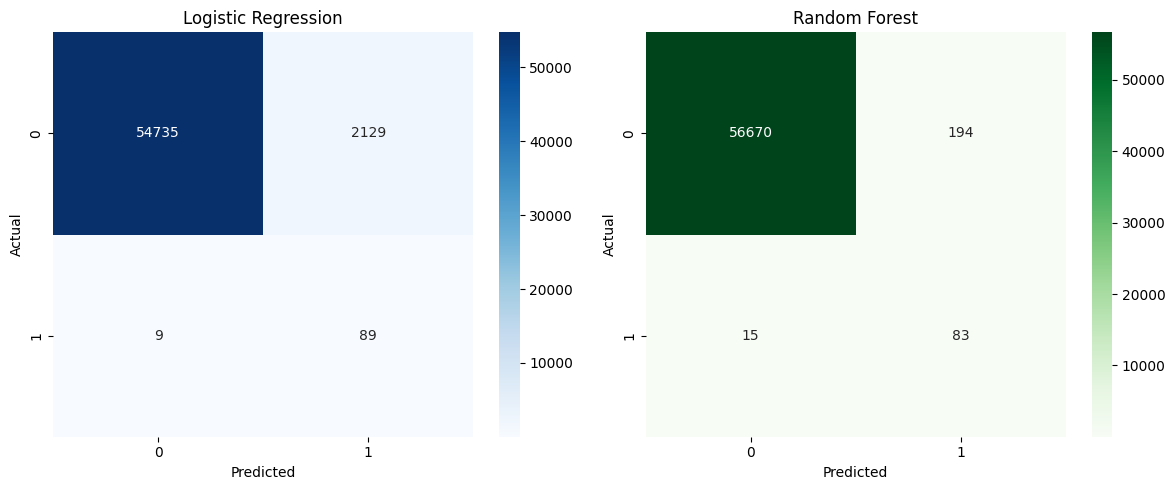

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression
sns.heatmap(
    confusion_matrix(y_test, lr_pred),
    annot=True, fmt="d", cmap="Blues", ax=axes[0]
)
axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Random Forest
sns.heatmap(
    confusion_matrix(y_test, rf_pred),
    annot=True, fmt="d", cmap="Greens", ax=axes[1]
)
axes[1].set_title("Random Forest")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [41]:
import os

os.makedirs("Screenshots", exist_ok=True)

print("Screenshots folder created successfully!")

Screenshots folder created successfully!


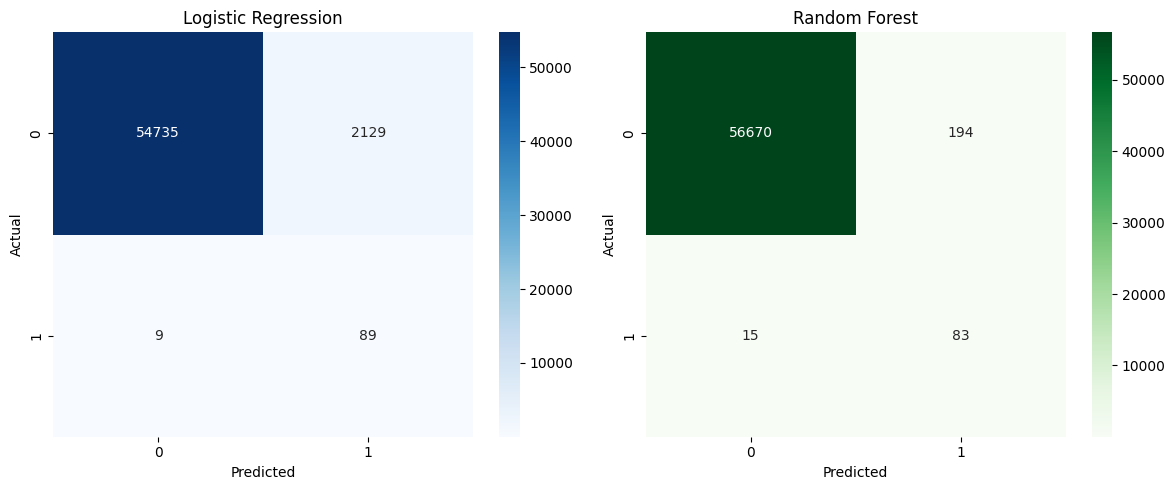

Confusion matrix graph saved successfully!


In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    confusion_matrix(y_test, lr_pred),
    annot=True, fmt="d", cmap="Blues", ax=axes[0]
)
axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    confusion_matrix(y_test, rf_pred),
    annot=True, fmt="d", cmap="Greens", ax=axes[1]
)
axes[1].set_title("Random Forest")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()

plt.savefig("Screenshots/confusion_matrices.png", dpi=300, bbox_inches="tight")

plt.show()

print("Confusion matrix graph saved successfully!")

In [43]:
from sklearn.metrics import roc_curve

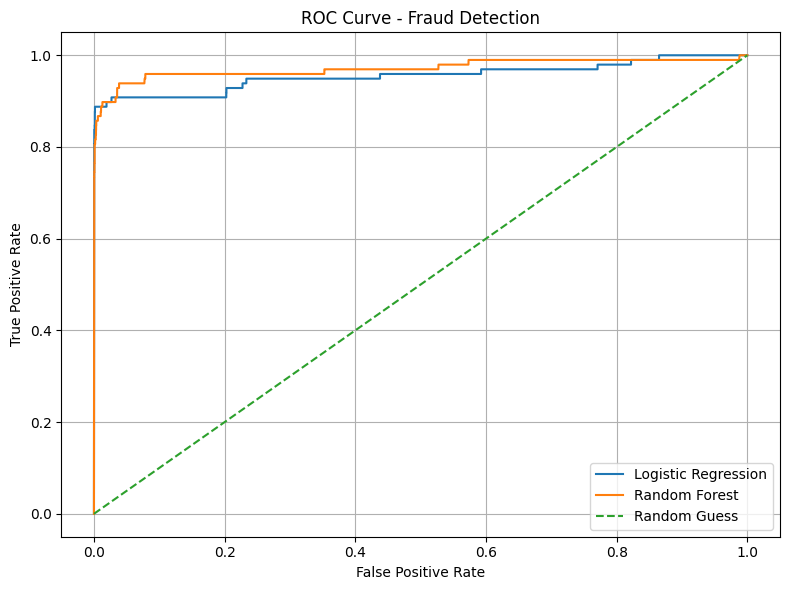

ROC curve saved successfully!


In [44]:
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_prob)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)

plt.figure(figsize=(8, 6))

plt.plot(lr_fpr, lr_tpr, label="Logistic Regression")
plt.plot(rf_fpr, rf_tpr, label="Random Forest")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Fraud Detection")
plt.legend()
plt.grid()
plt.tight_layout()

plt.savefig("Screenshots/roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

print("ROC curve saved successfully!")

In [45]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

feature_importance.head(10)

,Feature,Importance
14,V14,0.421318
17,V17,0.136197
10,V10,0.096860
12,V12,0.067554
4,V4,0.045132
2,V2,0.041023
19,V19,0.023168
18,V18,0.021391
21,V21,0.019535
3,V3,0.019283


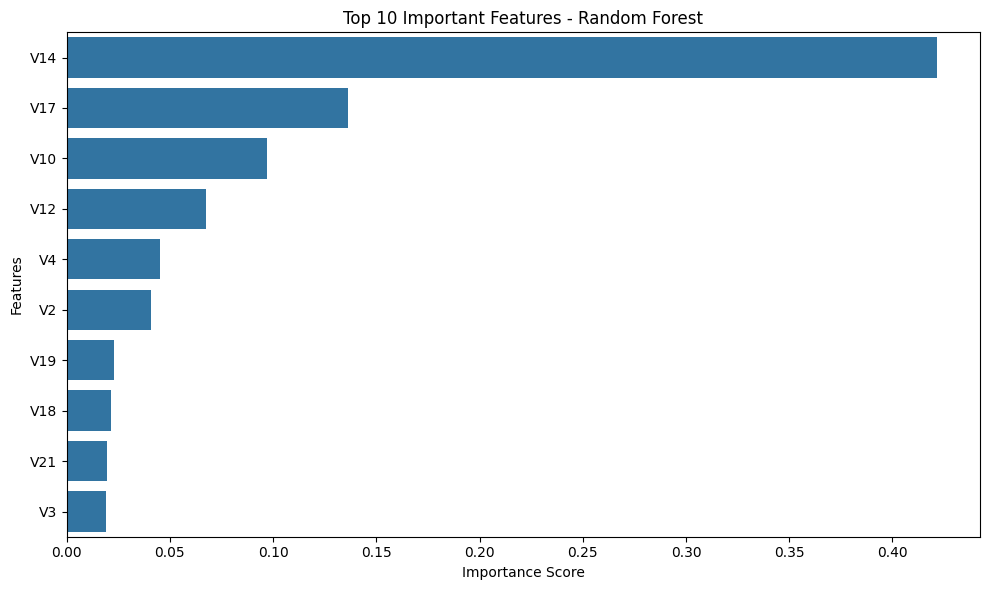

In [46]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()

plt.savefig("Screenshots/feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

In [47]:
feature_importance.to_csv(
    "Outputs/feature_importance.csv", index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


In [48]:
predictions = pd.DataFrame({
    "Actual": y_test.values,
    "Logistic_Regression_Predicted": lr_pred,
    "Random_Forest_Predicted": rf_pred,
    "Logistic_Regression_Probability": lr_prob,
    "Random_Forest_Probability": rf_prob
})

predictions.to_csv("Outputs/fraud_predictions.csv", index=False)

print("Fraud predictions saved successfully!")

Fraud predictions saved successfully!


In [49]:
comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.962466,0.040126,0.908163,0.076857,0.954905
1,Random Forest,0.996331,0.299639,0.846939,0.442667,0.971329


## Evaluation Metrics

1. Accuracy: Measures the overall correct predictions.
2. Precision: Measures how many predicted fraud cases are actually fraud.
3. Recall: Measures how many actual fraud cases are correctly detected.
4. F1 Score: Balances precision and recall.
5. ROC-AUC: Measures how well the model separates fraud and genuine transactions.

Recall is especially important in fraud detection because missing a fraudulent transaction can cause financial loss. However, precision is also important to avoid wrongly blocking genuine transactions.

In [50]:
## Handling Imbalanced Data Using SMOTE

The dataset contains very few fraudulent transactions compared to genuine transactions.

SMOTE (Synthetic Minority Over-sampling Technique) creates synthetic examples of the minority class.

It helps the model learn fraud patterns more effectively.

SMOTE is applied only to the training data to avoid data leakage.

SyntaxError: invalid syntax (3868937010.py, line 3)

## Handling Imbalanced Data Using SMOTE

The dataset contains very few fraudulent transactions compared to genuine transactions.

SMOTE (Synthetic Minority Over-sampling Technique) creates synthetic examples of the minority class.

It helps the model learn fraud patterns more effectively.

SMOTE is applied only to the training data to avoid data leakage.

## Feature Importance Analysis

Feature importance identifies the input features that contribute most to the Random Forest model's predictions.

It helps us understand which transaction characteristics influence fraud detection.

The top features are displayed using a bar chart.

## Scalability for 1 Million Transactions per Hour

1. 1 million transactions per hour is approximately 278 transactions per second.
2. Use distributed systems such as Apache Kafka and Apache Spark.
3. Deploy the trained model through a real-time prediction API.
4. Use efficient data processing and optimized models.
5. Monitor model performance continuously.
6. Retrain the model regularly using new transaction data.

This approach helps the fraud detection system process large transaction volumes efficiently.

## Conclusion

This project developed a machine learning system to detect fraudulent financial transactions.

The dataset was analyzed to understand class imbalance and transaction patterns.

SMOTE was used to handle the imbalanced dataset.

Logistic Regression and Random Forest models were trained and evaluated using Precision, Recall, F1 Score and ROC-AUC.

The project demonstrates how machine learning can help identify suspicious transactions and reduce financial fraud.

In [51]:
print("TOP 10 FEATURES IN FRAUD DETECTION")
display(feature_importance.head(10))

TOP 10 FEATURES IN FRAUD DETECTION


,Feature,Importance
14,V14,0.421318
17,V17,0.136197
10,V10,0.096860
12,V12,0.067554
4,V4,0.045132
2,V2,0.041023
19,V19,0.023168
18,V18,0.021391
21,V21,0.019535
3,V3,0.019283


In [52]:
print("FINAL MODEL COMPARISON")
display(comparison.round(4))

FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.9625,0.0401,0.9082,0.0769,0.9549
1,Random Forest,0.9963,0.2996,0.8469,0.4427,0.9713


In [53]:
best_model = comparison.loc[comparison["F1 Score"].idxmax(), "Model"]

print("Best Model based on F1 Score:", best_model)

Best Model based on F1 Score: Random Forest


In [54]:
print("FRAUD DETECTION PROJECT SUMMARY")
print("--------------------------------")
print("Total Transactions:", len(df))
print("Genuine Transactions:", (df["Class"] == 0).sum())
print("Fraudulent Transactions:", (df["Class"] == 1).sum())

print("\nModels Used:")
print("1. Logistic Regression")
print("2. Random Forest")

print("\nBest Model based on F1 Score:", best_model)
print("\nOutput files saved in Outputs folder.")
print("Graphs saved in Screenshots folder.")

FRAUD DETECTION PROJECT SUMMARY
--------------------------------
Total Transactions: 284807
Genuine Transactions: 284315
Fraudulent Transactions: 492

Models Used:
1. Logistic Regression
2. Random Forest

Best Model based on F1 Score: Random Forest

Output files saved in Outputs folder.
Graphs saved in Screenshots folder.


In [55]:
import os

files_to_check = [
    "Outputs/model_comparison.csv",
    "Outputs/feature_importance.csv",
    "Outputs/fraud_predictions.csv",
    "Screenshots/confusion_matrices.png",
    "Screenshots/roc_curve.png",
    "Screenshots/feature_importance.png"
]

for file in files_to_check:
    if os.path.exists(file):
        print("FOUND:", file)
    else:
        print("MISSING:", file)

FOUND: Outputs/model_comparison.csv
FOUND: Outputs/feature_importance.csv
FOUND: Outputs/fraud_predictions.csv
FOUND: Screenshots/confusion_matrices.png
FOUND: Screenshots/roc_curve.png
FOUND: Screenshots/feature_importance.png
